# Excess and aging inventory

Two reports that answer two different questions, and are easy to mix up.

| | Excess | Aging |
|---|---|---|
| Question | What will not sell through in time? | What has been sitting too long? |
| Based on | stock against forward demand | receipt history |
| Output | four tiers: normal, surplus, excess, over-excess | stock no recent receipt can account for |

This notebook rebuilds both on synthetic data, then replays a date-rule bug that dropped confirmed orders once their date slipped into last month.

> Clean-room version. Written from scratch on generated data with illustrative parameters (supply_ops/config.py).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.max_colwidth", 90)

from supply_ops import inventory, synthetic
from supply_ops.config import InventoryConfig
from supply_ops.plots import excess_tiers
from supply_ops.synthetic import AS_OF

stock, demand, receipts = synthetic.inventory()
print(f"{len(stock)} items, {len(demand):,} demand lines, {len(receipts):,} receipts, report date {AS_OF:%Y-%m-%d}")
stock["lifecycle"].value_counts()

160 items, 2,526 demand lines, 2,832 receipts, report date 2026-07-01


lifecycle
active      102
fading       28
dead         14
seasonal      8
rebought      8
Name: count, dtype: int64

## 1. Four tiers, from stock against forward demand

Walk down each item's stock: what the next 3 months will use is **normal**, what months 4-6 will use is **surplus**, anything beyond a full year of demand is **over-excess**, and the rest is **excess**. The tiers always add up to on-hand stock.

In [2]:
fixed = inventory.excess(stock, demand, AS_OF)
s_fixed = inventory.summary(fixed)
s_fixed[["normal", "surplus", "excess", "over_excess", "total_excess", "stock"]].map("${:,.0f}".format)

normal          $3,032,291
surplus         $1,551,659
excess            $566,389
over_excess       $814,301
total_excess    $1,380,689
stock           $5,964,639
dtype: object

## 2. The date rule that invented excess

The report runs on the first day of a month. A seasonal line was sold in on confirmed orders dated the last days of the previous month, not yet shipped. A rule that keeps only demand dated from the start of the current month drops those orders, and the stock reserved for them looks unclaimed.

In [3]:
bug = inventory.excess(stock, demand, AS_OF, fold_past_due=False)
s_bug = inventory.summary(bug)
phantom = s_bug["total_excess"] - s_fixed["total_excess"]
print(f"Excess with past-due orders dropped:   ${s_bug['total_excess']:,.0f}  ({s_bug['excess_share']:.1%} of stock)")
print(f"Excess with confirmed orders counted:  ${s_fixed['total_excess']:,.0f}  ({s_fixed['excess_share']:.1%} of stock)")
print(f"Excess that was not excess:            ${phantom:,.0f}")

seasonal = stock.loc[stock["lifecycle"] == "seasonal", "item"]
pd.DataFrame({
    "on_hand": bug.set_index("item").loc[seasonal, "on_hand"],
    "excess_with_bug": bug.set_index("item").loc[seasonal, "total_excess"].round(0),
    "excess_fixed": fixed.set_index("item").loc[seasonal, "total_excess"].round(0),
})

Excess with past-due orders dropped:   $1,691,495  (28.4% of stock)
Excess with confirmed orders counted:  $1,380,689  (23.1% of stock)
Excess that was not excess:            $310,806


,on_hand,excess_with_bug,excess_fixed
item,,,
N-001,40997,39426.0,4988.0
N-002,7776,7438.0,906.0
N-003,5715,5462.0,662.0
N-004,5372,5138.0,626.0
N-005,17571,16829.0,2069.0
N-006,19625,18812.0,2328.0
N-007,24971,23857.0,2881.0
N-008,16914,16210.0,2002.0


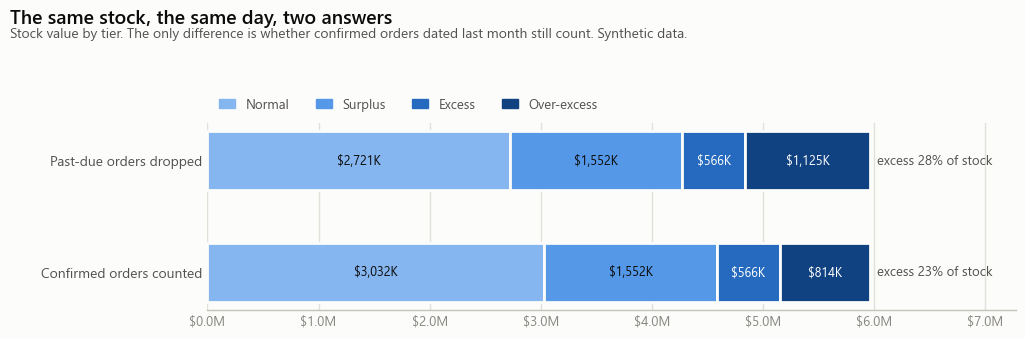

In [4]:
excess_tiers(s_bug, s_fixed, path=ROOT / "images" / "excess_tiers.png");

## 3. The fix is narrow on purpose

The rule: **a confirmed order counts as demand no matter how old its date is.** Folding *every* past-due line back in would be wrong the other way: old planned requirements nobody will ever order would absorb real excess and hide it.

In [5]:
fold_all = InventoryConfig(fold_past_due=("confirmed", "requisition", "forecast"))
s_all = inventory.summary(inventory.excess(stock, demand, AS_OF, cfg=fold_all))
hidden = s_fixed["total_excess"] - s_all["total_excess"]
print(f"Fold confirmed orders only:  ${s_fixed['total_excess']:,.0f}")
print(f"Fold every past-due line:    ${s_all['total_excess']:,.0f}  (${hidden:,.0f} of real excess hidden)")

Fold confirmed orders only:  $1,380,689
Fold every past-due line:    $1,358,013  ($22,676 of real excess hidden)


## 4. Aging: a different question

Aged stock is excess that the receipts inside the last 3 years cannot account for. It goes on the **write-off list** only if the item has not been received inside the window at all: stock that was bought again last year is an over-buy, a purchasing question, not dead stock.

In [6]:
aged = inventory.aged(fixed, receipts, AS_OF)
on_list = aged["write_off_list"]
print(f"Aged items: {len(aged)}, on the write-off list: {int(on_list.sum())} "
      f"(${aged.loc[on_list, 'aged_value'].sum():,.0f}), over-buys kept off it: {int((~on_list).sum())}")
aged.groupby(["lifecycle", "write_off_list"]).agg(items=("item", "size"), aged_value=("aged_value", "sum")).round(0)

Aged items: 22, on the write-off list: 14 ($291,485), over-buys kept off it: 8


,,items,aged_value
lifecycle,write_off_list,,
dead,True,14,291485.0
rebought,False,8,60254.0


In [7]:
aged.head(8)[["item", "lifecycle", "aged_units", "aged_value", "last_receipt", "write_off_list"]].round(0)

,item,lifecycle,aged_units,aged_value,last_receipt,write_off_list
0,N-012,dead,20223.0,46917.0,2021-10-01,True
1,N-009,dead,16035.0,38484.0,2022-03-01,True
2,N-019,dead,8852.0,32310.0,2022-01-01,True
3,N-013,dead,8665.0,31021.0,2022-06-01,True
4,N-016,dead,9882.0,25397.0,2023-01-01,True
5,N-015,dead,8869.0,21108.0,2022-04-01,True
6,N-022,dead,9397.0,20767.0,2022-01-01,True
7,N-014,dead,5482.0,18858.0,2022-06-01,True


## Key findings

- The same stock on the same day gives two different excess figures depending on one date rule. The difference is entirely stock that customers had already ordered.
- The fix counts confirmed orders as demand regardless of date, and nothing else: folding every past-due line hides real excess.
- Aging and excess are different questions. An item received again last year can be aged by quantity and still not belong on a write-off list.
- Dollars come first. The excess *share* of stock moves whenever healthy stock ships; the dollar figure is what a decision is about.